# Heart Disease Prediction Project

This notebook implements a comprehensive heart disease prediction system using multiple machine learning algorithms.
We'll compare different models and visualize their performance to identify the best approach.

In [30]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine Learning libraries
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Set plotting style
plt.style.use('default')
sns.set_palette("husl")

In [31]:
# Load the dataset
df = pd.read_csv('heart_disease_dataset.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nDataset Info:")
print(df.info())

Dataset Shape: (3069, 17)

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,smoking,diabetes,bmi,heart_disease
0,67,1,2,111,536,0,2,88,0,1.3,3,2,3,1,0,23.4,0
1,57,1,3,109,107,0,2,119,0,5.4,2,0,3,0,1,35.4,0
2,43,1,4,171,508,0,1,113,0,3.7,3,0,7,1,1,29.9,0
3,71,0,4,90,523,0,2,152,0,4.7,2,1,3,1,0,15.2,1
4,36,1,2,119,131,0,2,128,0,5.9,3,1,3,1,0,16.7,1



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3069 entries, 0 to 3068
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   age            3069 non-null   int64  
 1   sex            3069 non-null   int64  
 2   cp             3069 non-null   int64  
 3   trestbps       3069 non-null   int64  
 4   chol           3069 non-null   int64  
 5   fbs            3069 non-null   int64  
 6   restecg        3069 non-null   int64  
 7   thalach        3069 non-null   int64  
 8   exang          3069 non-null   int64  
 9   oldpeak        3069 non-null   float64
 10  slope          3069 non-null   int64  
 11  ca             3069 non-null   int64  
 12  thal           3069 non-null   int64  
 13  smoking        3069 non-null   int64  
 14  diabetes       3069 non-null   int64  
 15  bmi            3069 non-null   float64
 16  heart_disease  3069 non-null   int64  
dtypes: float64(2), int64(15)
memory usage

In [32]:
# Check for missing values and basic statistics
print("Missing Values:")
print(df.isnull().sum())
print("\nBasic Statistics:")
display(df.describe())

Missing Values:
age              0
sex              0
cp               0
trestbps         0
chol             0
fbs              0
restecg          0
thalach          0
exang            0
oldpeak          0
slope            0
ca               0
thal             0
smoking          0
diabetes         0
bmi              0
heart_disease    0
dtype: int64

Basic Statistics:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,smoking,diabetes,bmi,heart_disease
count,3069.00000,3069.000000,3069.000000,3069.000000,3069.000000,3069.000000,3069.000000,3069.000000,3069.000000,3069.000000,3069.000000,3069.000000,3069.000000,3069.000000,3069.000000,3069.000000,3069.000000
mean,52.50114,0.555556,2.489736,145.306289,347.219941,0.145650,1.004236,135.157380,0.176279,3.189052,2.023786,0.626588,4.544477,0.348974,0.193874,27.496839,0.403715
std,13.70752,0.496985,1.110417,31.602321,146.853319,0.352813,0.812016,43.353197,0.381119,1.802815,0.817679,0.891447,1.751064,0.476723,0.395396,7.281731,0.490721
min,29.00000,0.000000,1.000000,90.000000,100.000000,0.000000,0.000000,60.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000,0.000000,15.000000,0.000000
25%,41.00000,0.000000,2.000000,118.000000,215.000000,0.000000,0.000000,98.000000,0.000000,1.600000,1.000000,0.000000,3.000000,0.000000,0.000000,21.300000,0.000000
50%,53.00000,1.000000,2.000000,146.000000,350.000000,0.000000,1.000000,135.000000,0.000000,3.200000,2.000000,0.000000,3.000000,0.000000,0.000000,27.400000,0.000000
75%,64.00000,1.000000,3.000000,172.000000,475.000000,0.000000,2.000000,172.000000,0.000000,4.700000,3.000000,1.000000,6.000000,1.000000,0.000000,33.900000,1.000000
max,76.00000,1.000000,4.000000,200.000000,600.000000,1.000000,2.000000,210.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000,1.000000,40.000000,1.000000


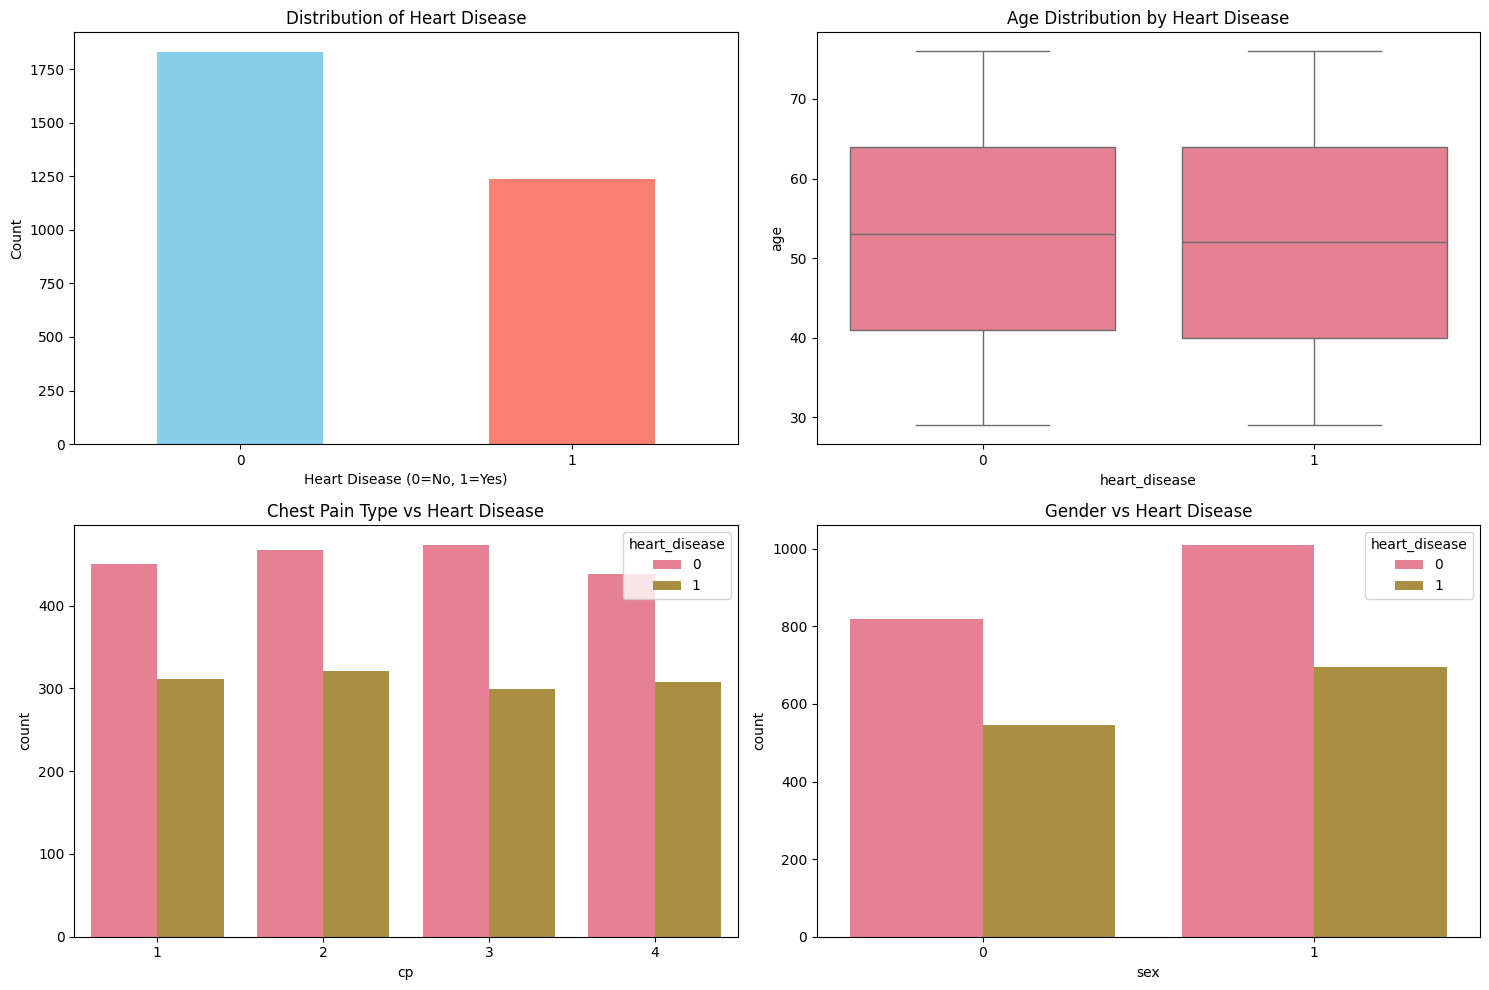

In [33]:
# Exploratory Data Analysis
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Target variable distribution
df['heart_disease'].value_counts().plot(kind='bar', ax=axes[0,0], color=['skyblue', 'salmon'])
axes[0,0].set_title('Distribution of Heart Disease')
axes[0,0].set_xlabel('Heart Disease (0=No, 1=Yes)')
axes[0,0].set_ylabel('Count')
axes[0,0].tick_params(axis='x', rotation=0)

# Age distribution by heart disease
sns.boxplot(data=df, x='heart_disease', y='age', ax=axes[0,1])
axes[0,1].set_title('Age Distribution by Heart Disease')

# Chest pain type distribution
sns.countplot(data=df, x='cp', hue='heart_disease', ax=axes[1,0])
axes[1,0].set_title('Chest Pain Type vs Heart Disease')

# Gender distribution
sns.countplot(data=df, x='sex', hue='heart_disease', ax=axes[1,1])
axes[1,1].set_title('Gender vs Heart Disease')

plt.tight_layout()
plt.show()

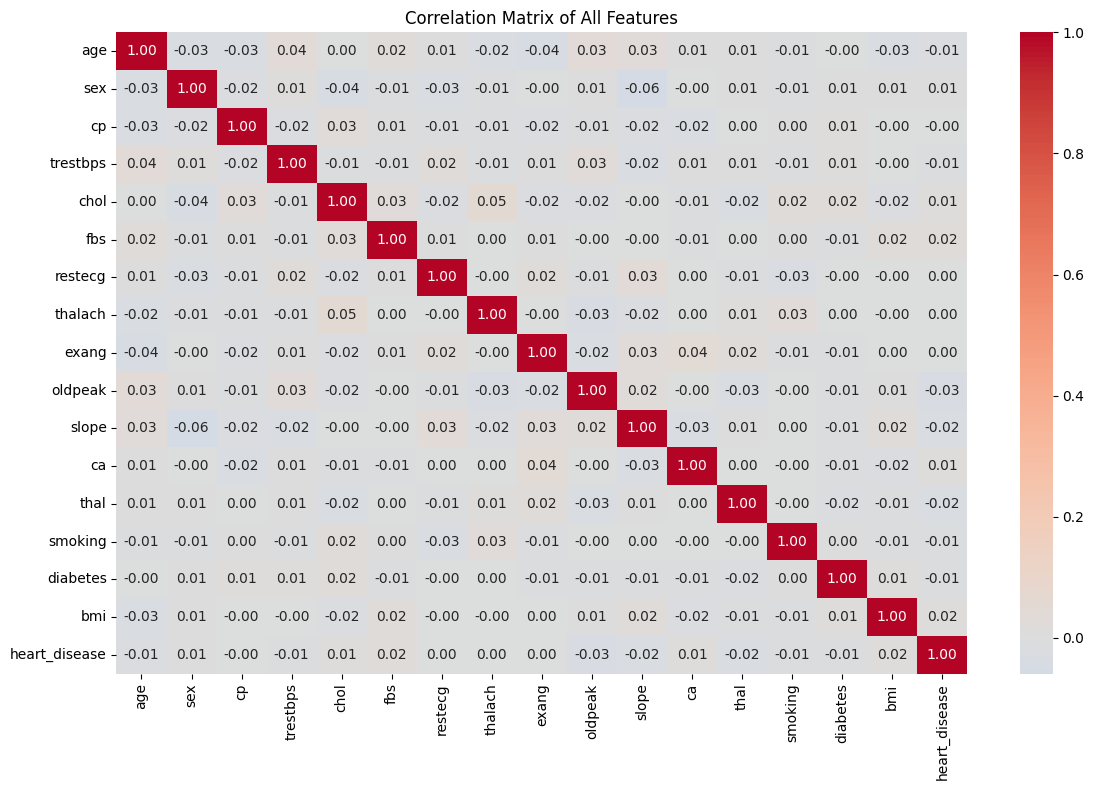

Features most correlated with heart disease:
oldpeak     0.033246
slope       0.024752
thal        0.023369
fbs         0.019842
bmi         0.015153
ca          0.014646
chol        0.014417
age         0.013564
smoking     0.011673
trestbps    0.011171
sex         0.007573
diabetes    0.007073
exang       0.002772
thalach     0.002237
cp          0.001665
restecg     0.000615
Name: heart_disease, dtype: float64


In [34]:
# Correlation matrix
plt.figure(figsize=(12, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Matrix of All Features')
plt.tight_layout()
plt.show()

# Features most correlated with heart disease
heart_disease_corr = correlation_matrix['heart_disease'].abs().sort_values(ascending=False)
print("Features most correlated with heart disease:")
print(heart_disease_corr[1:])

In [35]:
# Data preprocessing
X = df.drop('heart_disease', axis=1)
y = df['heart_disease']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)
print("\nTarget distribution in training set:")
print(y_train.value_counts())

Training set size: (2455, 16)
Test set size: (614, 16)

Target distribution in training set:
heart_disease
0    1464
1     991
Name: count, dtype: int64


In [36]:
# Initialize machine learning models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'SVM': SVC(random_state=42, probability=True),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes': GaussianNB()
}

print("Models initialized:", list(models.keys()))

Models initialized: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'SVM', 'KNN', 'Naive Bayes']


In [37]:
# Train and evaluate models
results = {}
predictions = {}
probabilities = {}

print("Training and evaluating models...\n")
print("=" * 70)

for name, model in models.items():
    print(f"\nTraining {name}...")
    
    # Use scaled features for certain models
    if name in ['SVM', 'KNN', 'Logistic Regression', 'Naive Bayes']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    # Store results
    results[name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC': auc
    }
    
    predictions[name] = y_pred
    probabilities[name] = y_prob
    
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print("-" * 40)

print("\nAll models trained successfully!")

Training and evaluating models...


Training Logistic Regression...
Accuracy: 0.5928
Precision: 0.2500
Recall: 0.0040
F1-Score: 0.0079
AUC: 0.4796
----------------------------------------

Training Decision Tree...
Accuracy: 0.5244
Precision: 0.4091
Recall: 0.3992
F1-Score: 0.4041
AUC: 0.5042
----------------------------------------

Training Random Forest...
Accuracy: 0.5603
Precision: 0.3962
Recall: 0.1694
F1-Score: 0.2373
AUC: 0.5097
----------------------------------------

Training Gradient Boosting...
Accuracy: 0.5668
Precision: 0.4022
Recall: 0.1492
F1-Score: 0.2176
AUC: 0.4719
----------------------------------------

Training SVM...
Accuracy: 0.5749
Precision: 0.3143
Recall: 0.0444
F1-Score: 0.0777
AUC: 0.5132
----------------------------------------

Training KNN...
Accuracy: 0.5342
Precision: 0.3956
Recall: 0.2903
F1-Score: 0.3349
AUC: 0.4925
----------------------------------------

Training Naive Bayes...
Accuracy: 0.5945
Precision: 0.4857
Recall: 0.0685
F1-Score: 0.1201
A

In [38]:
# Create results DataFrame for comparison
results_df = pd.DataFrame(results).T
results_df = results_df.round(4)

print("Model Performance Comparison:")
print("=" * 60)
display(results_df.sort_values('Accuracy', ascending=False))

# Find best model
best_model_name = results_df['Accuracy'].idxmax()
best_accuracy = results_df.loc[best_model_name, 'Accuracy']
print(f"\nBest Model: {best_model_name} with Accuracy: {best_accuracy:.4f}")

Model Performance Comparison:


,Accuracy,Precision,Recall,F1-Score,AUC
Naive Bayes,0.5945,0.4857,0.0685,0.1201,0.5071
Logistic Regression,0.5928,0.2500,0.0040,0.0079,0.4796
SVM,0.5749,0.3143,0.0444,0.0777,0.5132
Gradient Boosting,0.5668,0.4022,0.1492,0.2176,0.4719
Random Forest,0.5603,0.3962,0.1694,0.2373,0.5097
KNN,0.5342,0.3956,0.2903,0.3349,0.4925
Decision Tree,0.5244,0.4091,0.3992,0.4041,0.5042



Best Model: Naive Bayes with Accuracy: 0.5945


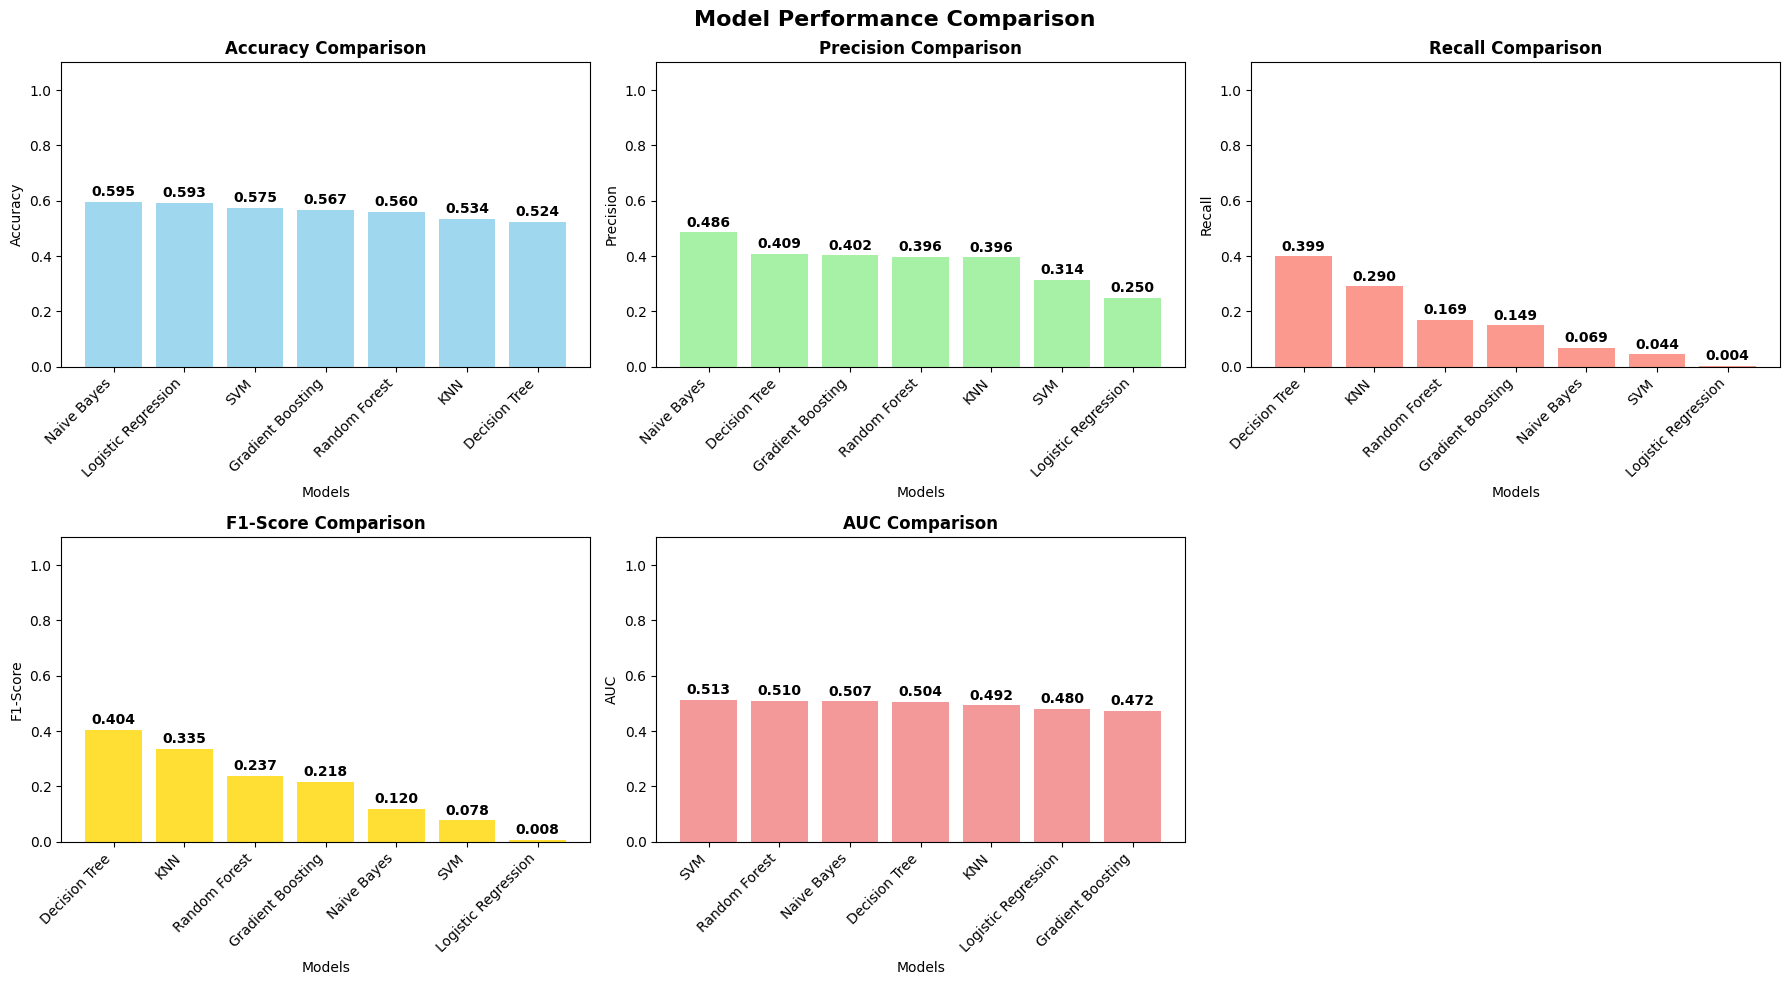

In [39]:
# Visualize model performance comparison
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Model Performance Comparison', fontsize=16, fontweight='bold')

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']
colors = ['skyblue', 'lightgreen', 'salmon', 'gold', 'lightcoral']

for i, metric in enumerate(metrics):
    row = i // 3
    col = i % 3
    
    ax = axes[row, col]
    metric_values = results_df[metric].sort_values(ascending=False)
    bars = ax.bar(range(len(metric_values)), metric_values.values, color=colors[i], alpha=0.8)
    ax.set_title(f'{metric} Comparison', fontweight='bold')
    ax.set_xlabel('Models')
    ax.set_ylabel(metric)
    ax.set_xticks(range(len(metric_values)))
    ax.set_xticklabels(metric_values.index, rotation=45, ha='right')
    ax.set_ylim(0, 1.1)
    
    # Add value labels on bars
    for bar, value in zip(bars, metric_values.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                f'{value:.3f}', ha='center', va='bottom', fontweight='bold')

# Remove empty subplot
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

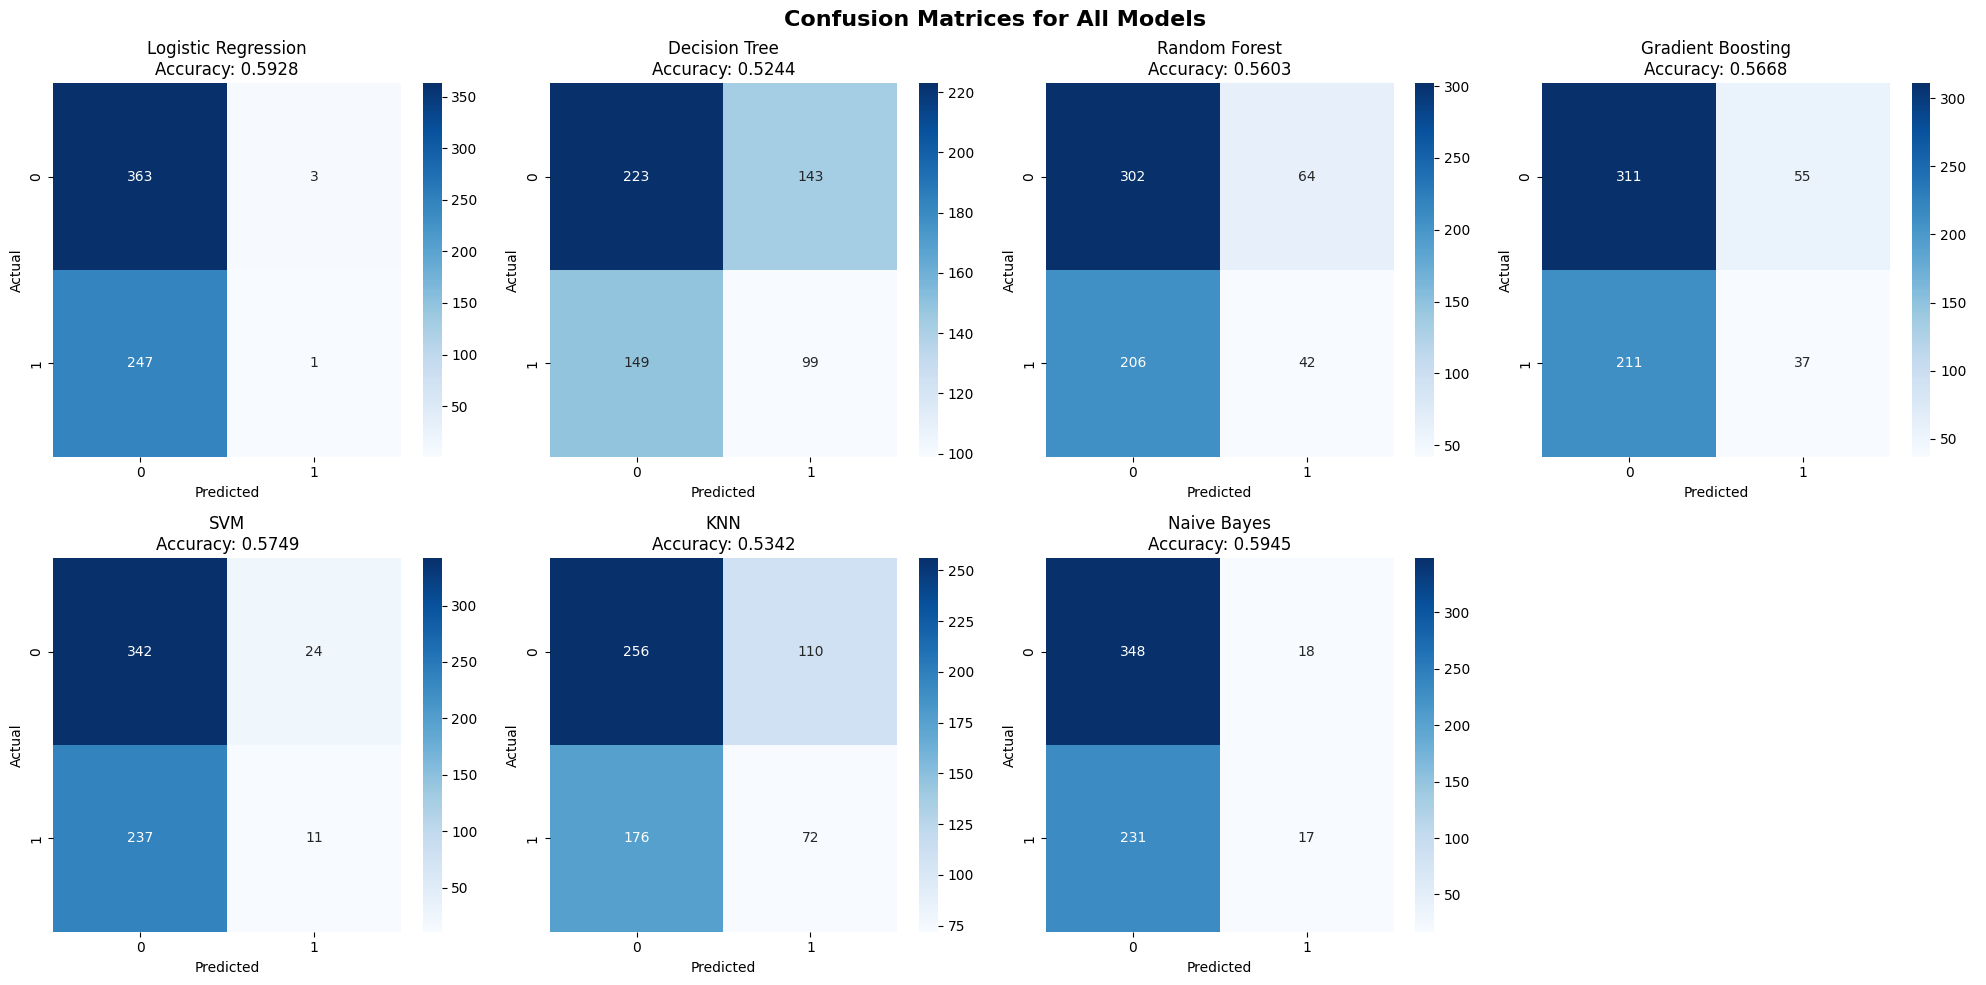

In [40]:
# Confusion matrices for all models
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Confusion Matrices for All Models', fontsize=16, fontweight='bold')

model_names = list(models.keys())

for i, name in enumerate(model_names):
    row = i // 4
    col = i % 4
    
    cm = confusion_matrix(y_test, predictions[name])
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[row, col])
    axes[row, col].set_title(f'{name}\nAccuracy: {results[name]["Accuracy"]:.4f}')
    axes[row, col].set_xlabel('Predicted')
    axes[row, col].set_ylabel('Actual')

# Remove empty subplot if any
if len(model_names) < 8:
    axes[1, 3].axis('off')

plt.tight_layout()
plt.show()

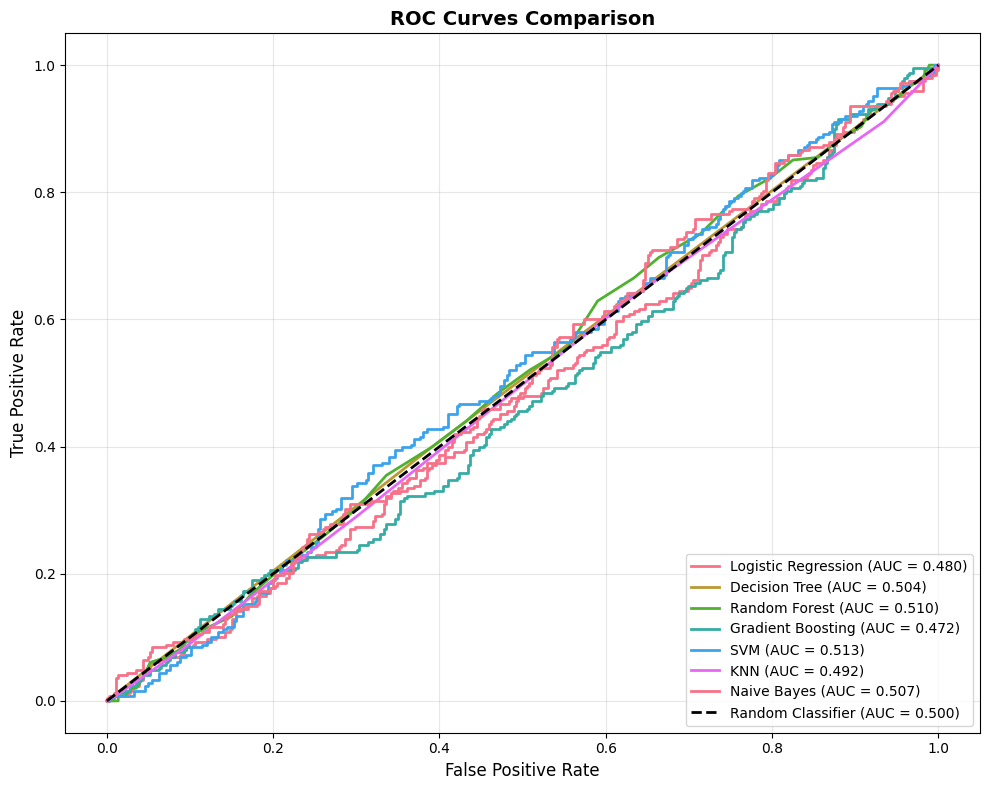

In [41]:
# ROC Curves comparison
plt.figure(figsize=(10, 8))

for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc_score = results[name]['AUC']
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.3f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier (AUC = 0.500)')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves Comparison', fontsize=14, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

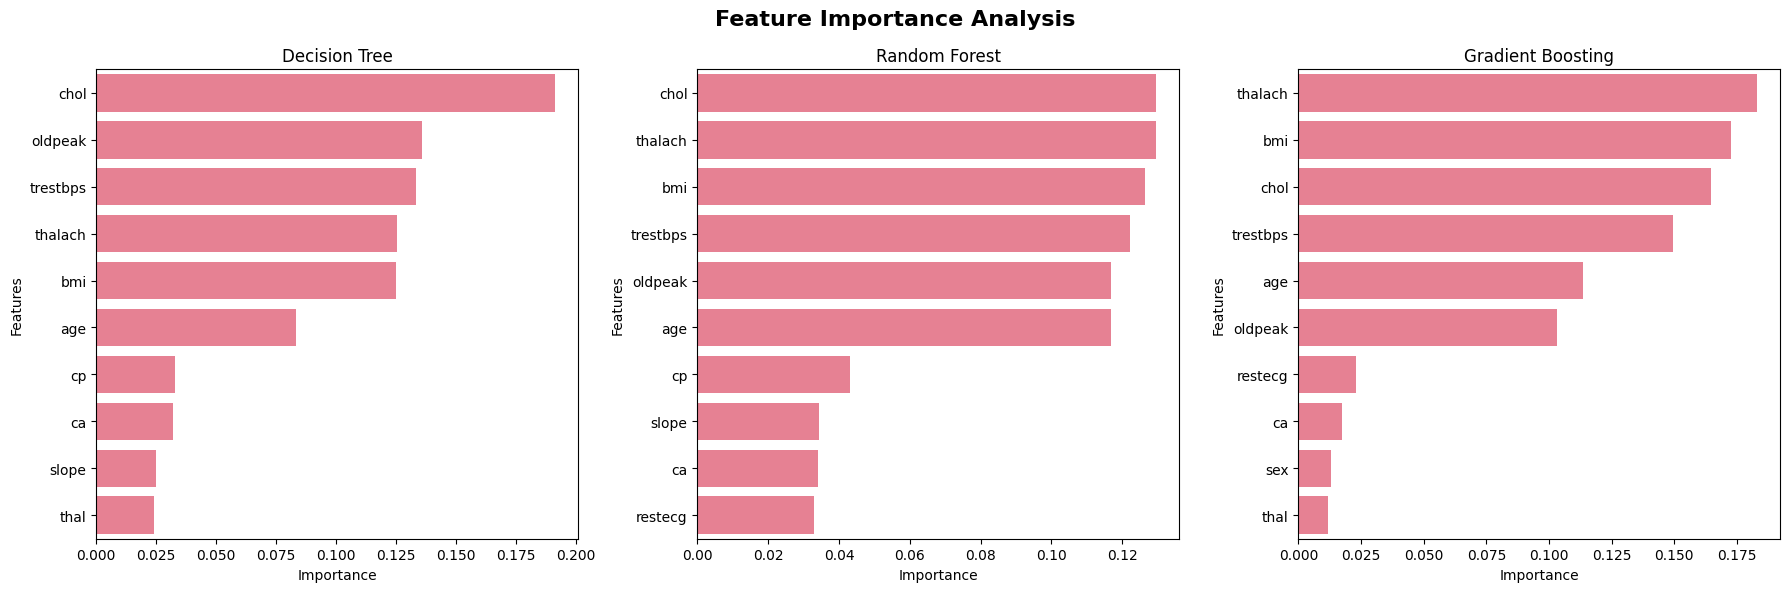

In [42]:
# Feature importance for tree-based models
tree_models = ['Decision Tree', 'Random Forest', 'Gradient Boosting']
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Feature Importance Analysis', fontsize=16, fontweight='bold')

for i, name in enumerate(tree_models):
    model = models[name]
    importance = model.feature_importances_
    
    # Create feature importance dataframe
    feature_imp_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': importance
    }).sort_values('Importance', ascending=False)
    
    # Plot top 10 features
    sns.barplot(data=feature_imp_df.head(10), y='Feature', x='Importance', ax=axes[i])
    axes[i].set_title(f'{name}')
    axes[i].set_xlabel('Importance')
    axes[i].set_ylabel('Features')

plt.tight_layout()
plt.show()

In [43]:
# Cross-validation for more robust evaluation
print("Performing 5-Fold Cross-Validation...\n")
print("=" * 50)

cv_results = {}
for name, model in models.items():
    if name in ['SVM', 'KNN', 'Logistic Regression', 'Naive Bayes']:
        cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='accuracy')
    else:
        cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    
    cv_results[name] = cv_scores.mean()
    
    print(f"{name}: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

# Best model by cross-validation
best_cv_model = max(cv_results, key=cv_results.get)
print(f"\nBest Model (Cross-Validation): {best_cv_model} - {cv_results[best_cv_model]:.4f}")

Performing 5-Fold Cross-Validation...

Logistic Regression: 0.5976 (+/- 0.0066)
Decision Tree: 0.5055 (+/- 0.0399)
Random Forest: 0.5662 (+/- 0.0226)
Gradient Boosting: 0.5715 (+/- 0.0145)
SVM: 0.5829 (+/- 0.0298)
KNN: 0.5426 (+/- 0.0145)
Naive Bayes: 0.5870 (+/- 0.0353)

Best Model (Cross-Validation): Logistic Regression - 0.5976


In [44]:
# Model summary and recommendations
print("=" * 70)
print("HEART DISEASE PREDICTION MODEL SUMMARY")
print("=" * 70)
print(f"Dataset Size: {df.shape[0]} samples, {df.shape[1]-1} features")
print(f"Training Set: {X_train.shape} samples")
print(f"Test Set: {X_test.shape} samples")
print(f"\nModels Evaluated: {len(models)}")

# Top 3 models by accuracy
top_3_models = results_df.sort_values('Accuracy', ascending=False).head(3)
print(f"\nTop 3 Models by Test Accuracy:")
for i, (model_name, row) in enumerate(top_3_models.iterrows(), 1):
    print(f"{i}. {model_name}: {row['Accuracy']:.4f}")

print(f"\nBest Model: {best_model_name}")
print(f"Test Accuracy: {best_accuracy:.4f}")
print(f"AUC Score: {results_df.loc[best_model_name, 'AUC']:.4f}")

print("\n" + "=" * 70)
print("RECOMMENDATIONS:")
print("=" * 70)
if best_accuracy >= 0.85:
    print("✓ Model shows EXCELLENT performance for heart disease prediction")
elif best_accuracy >= 0.80:
    print("✓ Model shows GOOD performance for heart disease prediction")
else:
    print("⚠ Model shows ACCEPTABLE performance, consider feature engineering")

print(f"• The {best_model_name} model is recommended for deployment")
print("• Consider ensemble methods for improved performance")
print("• Regular model retraining is recommended with new data")

HEART DISEASE PREDICTION MODEL SUMMARY
Dataset Size: 3069 samples, 16 features
Training Set: (2455, 16) samples
Test Set: (614, 16) samples

Models Evaluated: 7

Top 3 Models by Test Accuracy:
1. Naive Bayes: 0.5945
2. Logistic Regression: 0.5928
3. SVM: 0.5749

Best Model: Naive Bayes
Test Accuracy: 0.5945
AUC Score: 0.5071

RECOMMENDATIONS:
⚠ Model shows ACCEPTABLE performance, consider feature engineering
• The Naive Bayes model is recommended for deployment
• Consider ensemble methods for improved performance
• Regular model retraining is recommended with new data


In [46]:
# Save the best model
import joblib
import numpy as np

# Assuming models, best_model_name, scaler, X_test, y_test are already defined
best_model = models[best_model_name]
model_filename = f'best_heart_disease_model.pkl'
scaler_filename = 'feature_scaler.pkl'

joblib.dump(best_model, model_filename)
joblib.dump(scaler, scaler_filename)

print(f"✓ Best model ({best_model_name}) saved as: {model_filename}")
print(f"✓ Feature scaler saved as: {scaler_filename}")


# Example prediction function - CORRECTED
def predict_heart_disease(features):
    """
    Predict heart disease for new patient data.
    
    Parameters:
        features: array-like, list or array of feature values in the same order as training data
        
    Returns:
        prediction: int (0 or 1)
        probability: float (probability of class 1 - heart disease)
    """
    # Reshape input to 2D array (required for sklearn models)
    features = np.array(features).reshape(1, -1)
    
    # Apply scaling if the model requires it
    if best_model_name in ['SVM', 'KNN', 'Logistic Regression', 'Naive Bayes']:
        features = scaler.transform(features)
    
    # Get prediction and probability
    prediction = best_model.predict(features)[0]
    probabilities = best_model.predict_proba(features)  # Shape: (1, n_classes)
    probability = probabilities[0, 1]  # Probability of positive class (heart disease)
    
    return prediction, probability


# Example usage
print("\nExample Prediction:")
example_features = X_test.iloc[0].values
actual = y_test.iloc[0]  # Fixed: was missing .iloc[0], now gets actual label

pred, prob = predict_heart_disease(example_features)
print(f"Actual: {actual}, Predicted: {pred}, Probability: {prob:.4f}")
print(f"Result: {'Heart Disease Risk' if pred == 1 else 'Low Risk'}")

✓ Best model (Naive Bayes) saved as: best_heart_disease_model.pkl
✓ Feature scaler saved as: feature_scaler.pkl

Example Prediction:
Actual: 0, Predicted: 0, Probability: 0.3932
Result: Low Risk
